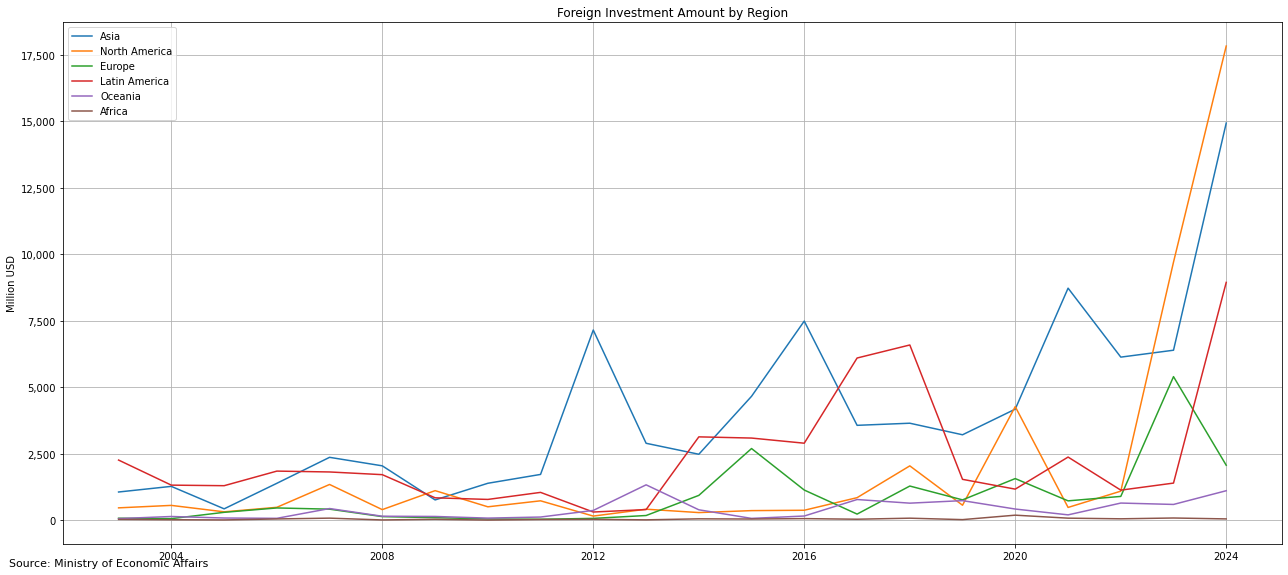

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

file_path = "對外投資金額及件數 州別.xlsx"
years = list(range(2024, 2002, -1))
columns = ["Region"] + [str(y) for y in years]

amount_df = pd.read_excel(file_path, skiprows=2, nrows=6, header=None)
amount_df.columns = columns
amount_df.set_index("Region", inplace=True)
amount_df = amount_df[~amount_df.index.str.contains("合計|總計|Total", na=False)]

amount_T = amount_df.T
amount_T.index = pd.to_datetime(amount_T.index, format="%Y")

formatter = FuncFormatter(lambda x, _: f"{x:,.0f}")

fig, ax = plt.subplots(figsize=(18, 8))

for region in amount_T.columns:
    series = amount_T[region].dropna()
    ax.plot(series.index, series, label=region)
    values = series.values
    dates = series.index
    
ax.set_title("Foreign Investment Amount by Region")
ax.set_ylabel("Million USD")
ax.legend()
ax.grid(True)
ax.yaxis.set_major_formatter(formatter)

plt.figtext(0.01, 0.01, "Source: Ministry of Economic Affairs", ha='left', fontsize=11)
plt.tight_layout()
plt.show()

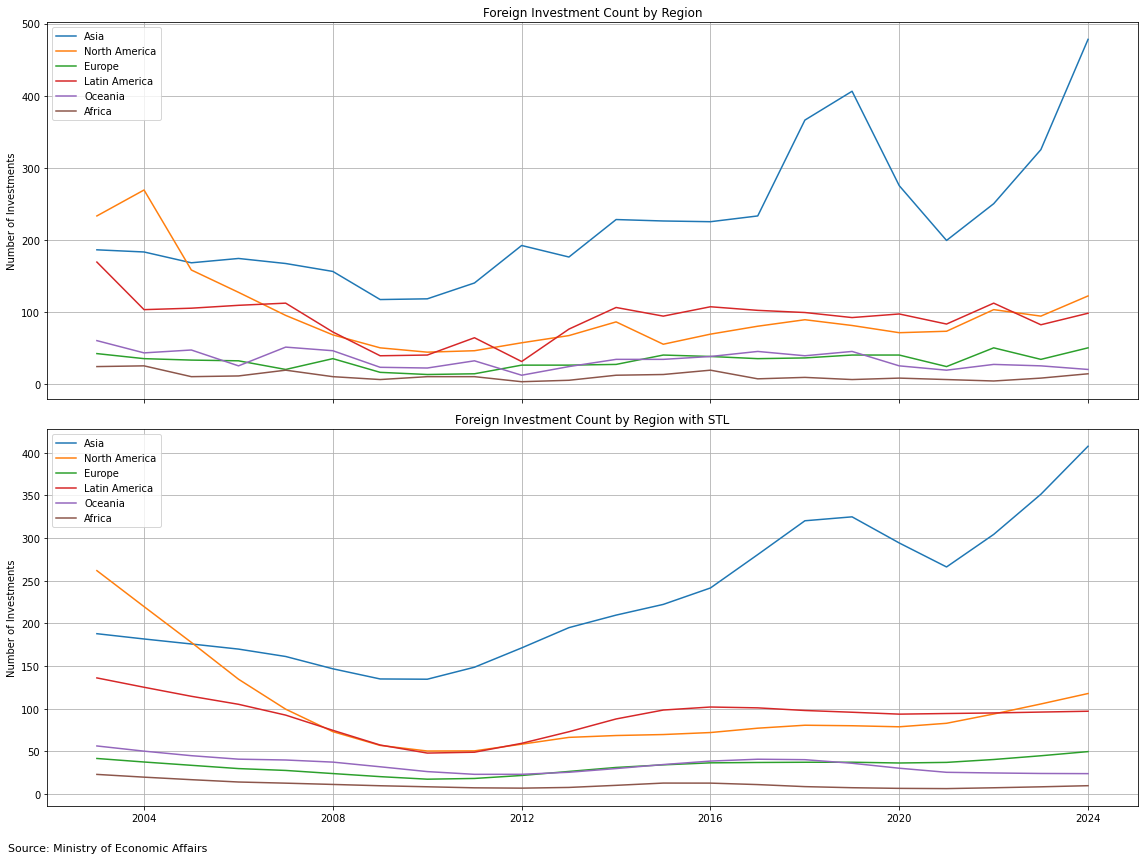

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL
from matplotlib.ticker import FuncFormatter
file_path = "對外投資金額及件數 州別.xlsx"

years = list(range(2024, 2002, -1))
columns = ["Region"] + [str(y) for y in years]

count_df = pd.read_excel(file_path, skiprows=11, header=None)
count_df.columns = columns
count_df.set_index("Region", inplace=True)
count_df = count_df[~count_df.index.str.contains("合計|總計|Total", na=False)]

count_T = count_df.T
count_T.index = pd.to_datetime(count_T.index, format="%Y")

formatter = FuncFormatter(lambda x, _: f"{x:,.0f}")

fig, axes = plt.subplots(2, 1, figsize=(16, 12), sharex=True)
for region in count_T.columns:
    axes[0].plot(count_T.index, count_T[region], label=region)
axes[0].set_title("Foreign Investment Count by Region")
axes[0].set_ylabel("Number of Investments")
axes[0].legend()
axes[0].grid(True)
axes[0].yaxis.set_major_formatter(formatter)
plt.tight_layout()

for region in count_T.columns:
    series = count_T[region].dropna()
    if len(series) >= 4:
        stl = STL(series, period=3)
        trend = stl.fit().trend
        axes[1].plot(trend.index, trend, label=region)
axes[1].set_title("Foreign Investment Count by Region with STL")
axes[1].set_ylabel("Number of Investments")
axes[1].legend()
axes[1].grid(True)
axes[1].yaxis.set_major_formatter(formatter)

plt.figtext(0.01, 0.01, "Source: Ministry of Economic Affairs", ha='left', fontsize=11)

plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.show()